In [2]:
%mamba install pandas numpy matplotlib scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.121 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ certifi             2026.10.23  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ pandas              3.1.0       np23py313h124dbc7_0  emscripten-forge-4x
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
file_path = "CaliforniaHousing.csv"
df = pd.read_csv(file_path)

display(df.head())
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print("\nData Types:\n", df.dtypes)
display(df.describe())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Records:", df.duplicated().sum())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Number of rows: 5
Number of columns: 10

Data Types:
 longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,-122.238000,37.858000,43.600000,2469.400000,388.000000,868.400000,383.800000,6.674660,369340.000000
std,0.013038,0.013038,13.501852,2603.018114,405.241286,862.336535,424.493463,1.921878,47089.733488
min,-122.250000,37.850000,21.000000,880.000000,129.000000,322.000000,126.000000,3.846200,341300.000000
25%,-122.250000,37.850000,41.000000,1274.000000,190.000000,496.000000,177.000000,5.643100,342200.000000
50%,-122.240000,37.850000,52.000000,1467.000000,235.000000,558.000000,219.000000,7.257400,352100.000000
75%,-122.230000,37.860000,52.000000,1627.000000,280.000000,565.000000,259.000000,8.301400,358500.000000
max,-122.220000,37.880000,52.000000,7099.000000,1106.000000,2401.000000,1138.000000,8.325200,452600.000000



Missing Values:
 longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

Duplicate Records: 0


In [23]:
df = df.dropna()
df = df.drop_duplicates()
print(f"Data cleaned. Remaining rows: {df.shape[0]}")

Data cleaned. Remaining rows: 5


In [24]:
X = df[['median_income']]  
y = df['median_house_value']

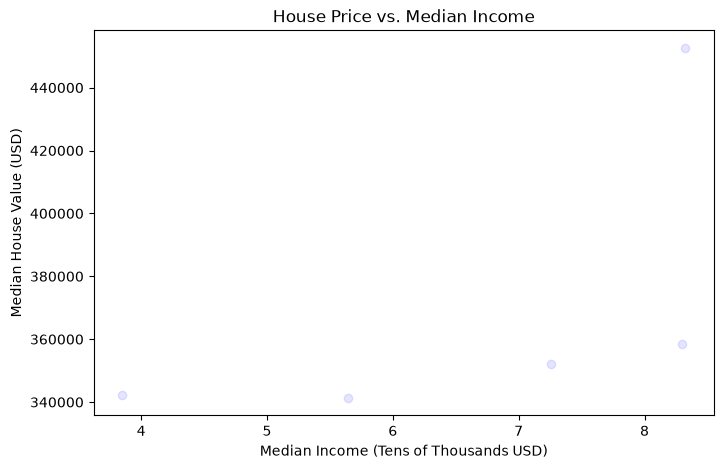

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.1, color='blue') 
plt.title("House Price vs. Median Income")
plt.xlabel("Median Income (Tens of Thousands USD)")
plt.ylabel("Median House Value (USD)")
plt.show()

In [31]:
# Changed test_size to 0.4 so the test set gets at least 2 rows from the 5-row sample
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print(f"Training observations: {X_train.shape[0]}")
print(f"Testing observations: {X_test.shape[0]}")

Training observations: 3
Testing observations: 2


In [32]:
model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
coefficient = model.coef_[0]

print(f"Intercept (c): {intercept:.4f}")
print(f"Coefficient (m): {coefficient:.4f}")

Intercept (c): 108256.3981
Coefficient (m): 38690.3992


In [33]:
y_pred = model.predict(X_test)

results_df = pd.DataFrame({'Actual Price': y_test, 'Predicted Price': y_pred})
display(results_df.head(10))

,Actual Price,Predicted Price
1,358500.0,429440.877786
4,342200.0,257067.411391


In [30]:
# Changed test_size to 0.4 so the test set gets at least 2 rows from the 5-row sample
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

print(f"Training observations: {X_train.shape[0]}")
print(f"Testing observations: {X_test.shape[0]}")

Training observations: 3
Testing observations: 2


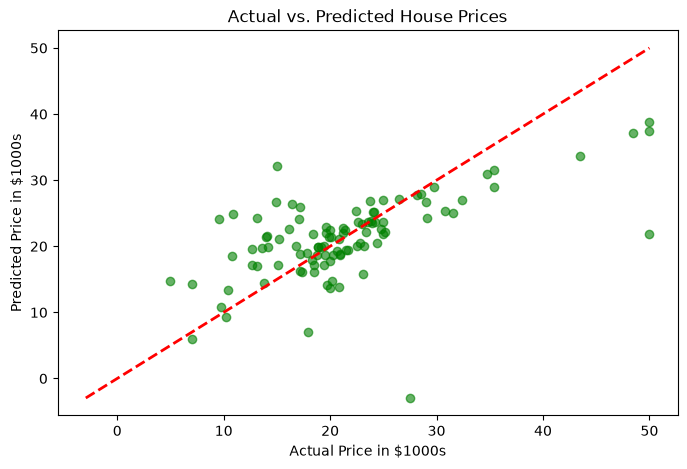

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='green')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

plt.title("Actual vs. Predicted House Prices")
plt.xlabel("Actual Price in $1000s")
plt.ylabel("Predicted Price in $1000s")
plt.show()

In [18]:
# Predict a new example using a DataFrame to match the training feature name
new_house_rooms = pd.DataFrame({'rm': [6.5]}) 
new_prediction = model.predict(new_house_rooms)

print(f"Predicted price for a house with 6.5 rooms: ${new_prediction[0] * 1000:,.2f}")

Predicted price for a house with 6.5 rooms: $24,517.64
